# Football scores: the full score distribution and the betting markets

The goals notebook models the number of goals of each side. This one models
the **joint distribution of the score** $(x, y)$ of a match, fitted to the
observed scores, and derives from it the probabilities of the usual markets:
home win / draw / away win (1X2) and over/under 2.5 goals, with standard
errors.

The functions used here are those of
[`docs/examples/football_scores.py`](../examples/football_scores.py).

## 1. Theory

### Two Poisson distributions, one score

For home team $i$ and away team $j$ the goals of each side are independent
Poisson variables,

$$
X \sim \mathrm{Poisson}(\lambda_{ij}),\quad
\log\lambda_{ij} = \alpha_i - \delta_j + \tfrac{\eta}{2},
\qquad
Y \sim \mathrm{Poisson}(\mu_{ij}),\quad
\log\mu_{ij} = \alpha_j - \delta_i - \tfrac{\eta}{2},
$$

so the probability of the score $(x, y)$ is the outer product
$P_{ij}(x, y) = p(x; \lambda_{ij})\,p(y; \mu_{ij})$. In `maxlike` this is a
`Product` of two `Poisson` distributions, one along each score axis.

### A finite grid: the censored tail

The model lives on a $K \times K$ grid ($K = 8$, goals $0, \dots, 7$). The
data record any score above 7 as 7, so the last cell must mean "7 or more":

$$
p(k;\lambda) = e^{-\lambda}\frac{\lambda^k}{k!}\ \ (k < K - 1),
\qquad
p(K-1;\lambda) = 1 - \sum_{k < K-1} p(k;\lambda) .
$$

This is `Poisson(K, normalised=True)` (tail `"censor"`, the default). Its
derivatives in $\lambda$ have a closed form, $\partial_\lambda p(k) = p(k-1) - p(k)$,
which keeps the Hessian exact.

### Likelihood

With $N_{ij}(x, y)$ the number of matches between $i$ and $j$ that ended
$x$–$y$, the likelihood is multinomial (`maxlike.Finite(dim=2)`):

$$
\ell(\theta) = \sum_{i,j,x,y} N_{ij}(x, y)\,\log P_{ij}(x, y) .
$$

The same identification constraint as for goals, $\sum\alpha + \sum\delta = 0$,
removes the common shift of attacks and defences.

### Markets are functions of the score matrix

$$
P(\text{home win}) = \sum_{x > y} P_{ij}(x, y), \quad
P(\text{draw}) = \sum_{x = y} P_{ij}(x, y), \quad
P(\text{over } 2.5) = \sum_{x + y > 2.5} P_{ij}(x, y) .
$$

`CollapseMatrix` computes such sums from linear conditions $a x + b y + c > 0$
(or $= 0$), with their derivatives. The standard errors follow from the delta
method, $\mathrm{var}(f) \approx J\,\widehat{\mathrm{cov}}(\hat\theta)\,J^\top$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plot_style as ps          # also puts the package and the examples on the path
from plot_style import BLUE, ORANGE, AQUA, TEXT_2, SEQUENTIAL
from maxlike.func import CollapseMatrix
import football_scores as ex

ps.apply()

## 2. Data

The same season as the goals notebook. How often each score occurred:

612 matches


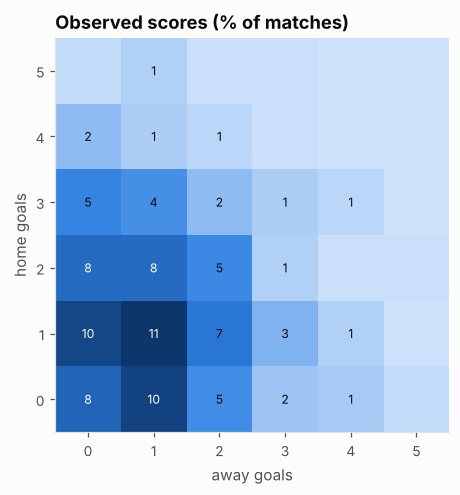

In [2]:
matches = pd.read_csv(ex.DATA)
K = ex.MAX_GOALS
x = np.minimum(matches["g1"], K - 1)
y = np.minimum(matches["g2"], K - 1)
observed = np.zeros((K, K))
np.add.at(observed, (x, y), 1)
observed /= observed.sum()
print(len(matches), "matches")


def score_heatmap(ax, P, title, vmax):
    show = 6                                  # 0..5 goals on screen
    im = ax.imshow(P[:show, :show], cmap=SEQUENTIAL, vmin=0, vmax=vmax, origin="lower")
    for a in range(show):
        for b in range(show):
            v = P[a, b]
            if v >= 0.005:
                ax.text(b, a, "%.0f" % (100 * v), ha="center", va="center", fontsize=8,
                        color="#fcfcfb" if v > 0.6 * vmax else "#0b0b0b")
    ax.set_xticks(range(show)); ax.set_yticks(range(show))
    ax.set_xlabel("away goals"); ax.set_ylabel("home goals")
    ax.set_title(title)
    ax.grid(False)
    return im


fig, ax = plt.subplots(figsize=(5, 4.6))
score_heatmap(ax, observed, "Observed scores (% of matches)", observed.max())
plt.tight_layout()

## 3. Model, data and fit

The score counts go into an array indexed by (home team, away team, home goals,
away goals); `prepare_series` builds it from the list of matches.

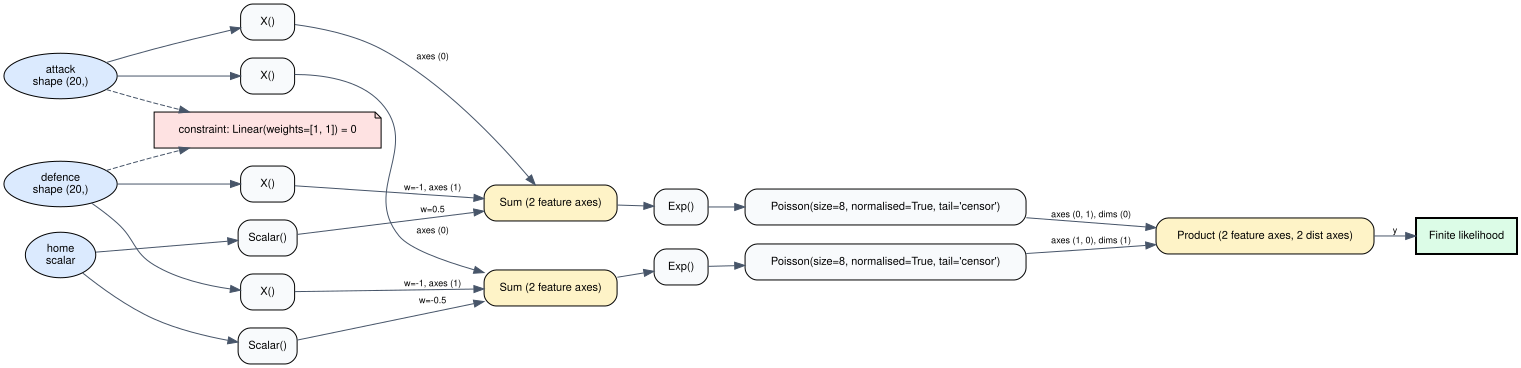

In [3]:
mle, teams = ex.fit()
mle.graph()

The graph reads from left to right: each rate is a `Sum` of an attack, a
defence and the home term, goes through `Exp` into a censored `Poisson`
distribution, and the two distributions meet in the `Product` that gives the
score matrix.

In [4]:
s = mle.summary()
print("home advantage: %.3f +/- %.3f" % tuple(s.loc[("home", ""), ["estimate", "std_error"]]))
strength = (s.loc["attack", "estimate"] + s.loc["defence", "estimate"]).sort_values(ascending=False)
strength.head(5).round(3).to_frame("attack + defence")

home advantage: 0.276 +/- 0.051


,attack + defence
label,
Team 03,1.365
Team 02,1.038
Team 11,0.945
Team 06,0.426
Team 15,0.087


**Fitted against observed scores.** Averaged over the matches played, the
model's score matrix should reproduce the observed frequencies. Each cell is
a percentage of matches.

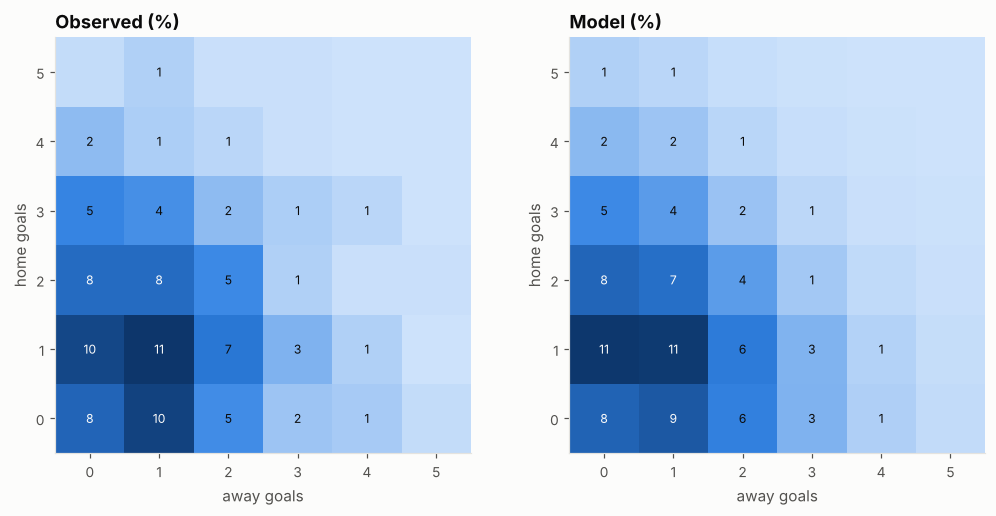

In [5]:
P = mle.predict()                              # [home, away, x, y]
pairs = (matches["t1"].values, matches["t2"].values)
fitted = P[pairs].mean(0)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.6))
vmax = max(observed.max(), fitted.max())
score_heatmap(axes[0], observed, "Observed (%)", vmax)
score_heatmap(axes[1], fitted, "Model (%)", vmax)
plt.tight_layout()

## 4. One match

The score matrix of the strongest team at home against a mid-table team, and
the markets derived from it, with delta-method standard errors.

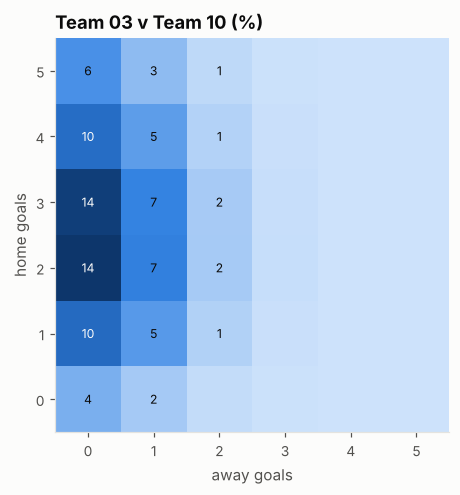

In [6]:
home_team = strength.index[0]
away_team = strength.index[len(teams) // 2]
i, j = teams.index(home_team), teams.index(away_team)

fig, ax = plt.subplots(figsize=(5, 4.6))
score_heatmap(ax, P[i, j], "%s v %s (%%)" % (home_team, away_team), P[i, j].max())
plt.tight_layout()

In [7]:
markets = {
    "home win": (CollapseMatrix(), 0), "draw": (CollapseMatrix(), 1),
    "away win": (CollapseMatrix(), 2),
    "over 2.5": (CollapseMatrix([(1, 1, -2.5, 1)]), 0),
    "under 2.5": (CollapseMatrix([(1, 1, -2.5, -1)]), 0),
}
rows = {}
for name, (collapse, k) in markets.items():
    value, se = mle.predict(collapse @ mle.model, se=True)
    rows[name] = (value[i, j, k], se[i, j, k])
pd.DataFrame(rows, index=["probability", "std_error"]).T.round(3)

,probability,std_error
home win,0.854,0.043
draw,0.106,0.028
away win,0.041,0.016
over 2.5,0.647,0.075
under 2.5,0.353,0.075


**Goal lines.** The probability of more than $L$ goals in the match, for each
line $L$, from the same score matrix: one fit prices every line consistently.

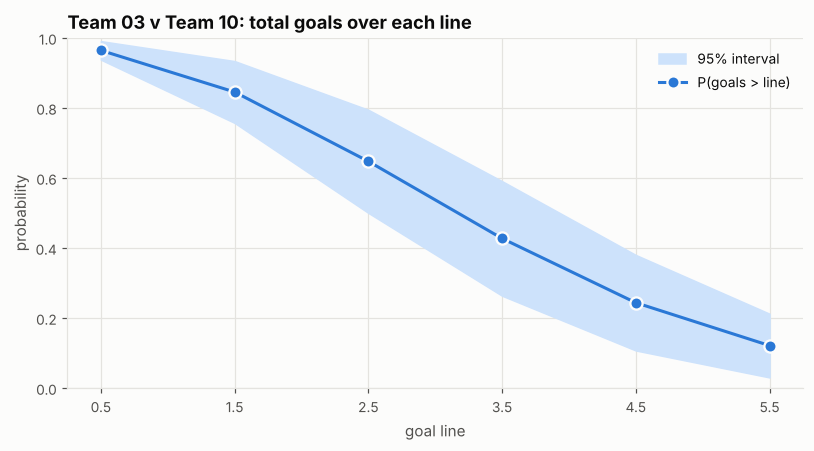

In [8]:
lines = np.arange(0.5, 6.5, 1.0)
over, over_se = [], []
for L in lines:
    v, e = mle.predict(CollapseMatrix([(1, 1, -L, 1)]) @ mle.model, se=True)
    over.append(v[i, j, 0]); over_se.append(e[i, j, 0])
over, over_se = np.array(over), np.array(over_se)

fig, ax = plt.subplots()
ax.fill_between(lines, over - 1.96 * over_se, over + 1.96 * over_se, color="#cde2fb", label="95% interval")
ax.plot(lines, over, "o-", color=BLUE, markersize=8, label="P(goals > line)",
        markeredgecolor="#fcfcfb", markeredgewidth=1.5)
ax.set_xticks(lines)
ax.set_ylim(0, 1)
ps.finish(ax, "%s v %s: total goals over each line" % (home_team, away_team),
          "goal line", "probability", legend=True)

## 5. Calibration of the 1X2 probabilities

For every match played, the model gives the probabilities of a home win, a
draw and an away win. Grouping the matches by predicted probability, the
share of matches with that outcome should match the prediction
(a *reliability diagram*). The fit uses these same matches, so this checks
the shape of the model, not its out-of-sample accuracy.

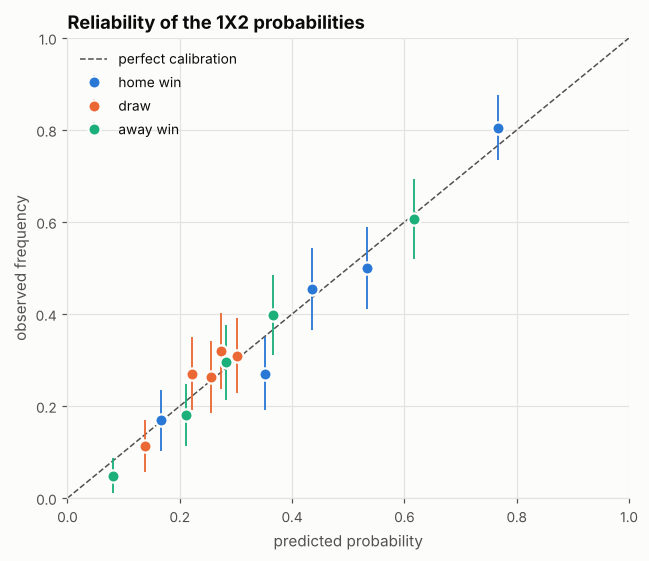

In [9]:
p1x2 = mle.predict(CollapseMatrix() @ mle.model)[pairs]       # [match, 3]
outcome = np.select([matches["g1"] > matches["g2"], matches["g1"] == matches["g2"]], [0, 1], 2)

fig, ax = plt.subplots(figsize=(6, 5.2))
ax.plot([0, 1], [0, 1], color=TEXT_2, lw=1, ls="--", label="perfect calibration")
for k, (label, color) in enumerate(zip(["home win", "draw", "away win"], [BLUE, ORANGE, AQUA])):
    p, hit = p1x2[:, k], (outcome == k).astype(float)
    bins = pd.qcut(p, 5, duplicates="drop")
    g = pd.DataFrame({"p": p, "hit": hit}).groupby(bins, observed=True)
    mp, mh, n = g["p"].mean(), g["hit"].mean(), g["hit"].count()
    half = 1.96 * np.sqrt(mh * (1 - mh) / n)
    ax.errorbar(mp, mh, yerr=half, fmt="o", color=color, markersize=8, elinewidth=1.2,
                markeredgecolor="#fcfcfb", markeredgewidth=1.5, label=label)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ps.finish(ax, "Reliability of the 1X2 probabilities", "predicted probability",
          "observed frequency", legend=True)

The probabilities follow the diagonal within their intervals for all three
outcomes. The draw is the hardest outcome for an independent-Poisson model
(its probabilities vary little across matches); a correlation term between the
two scores would be the next refinement.